In [1]:

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)


import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))


import kagglehub

df = pd.read_csv('/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv')
df.head()

/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 1.Dataset

In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [3]:
df.isna().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [4]:
df.duplicated().sum()

np.int64(0)

In [5]:
df["Churn"].value_counts(normalize=True) * 100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

In [6]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

df["TotalCharges"].isna().sum()

np.int64(11)

In [7]:
df[df["TotalCharges"].isna()]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


In [8]:
df.loc[
    df["TotalCharges"].isna(),
    ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]
]


,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,NaN,No
753,0,20.25,NaN,No
936,0,80.85,NaN,No
1082,0,25.75,NaN,No
1340,0,56.05,NaN,No
3331,0,19.85,NaN,No
3826,0,25.35,NaN,No
4380,0,20.00,NaN,No
5218,0,19.70,NaN,No
6670,0,73.35,NaN,No


In [9]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

In [10]:
df["TotalCharges"].isna().sum()

np.int64(0)

<Axes: xlabel='Contract', ylabel='count'>

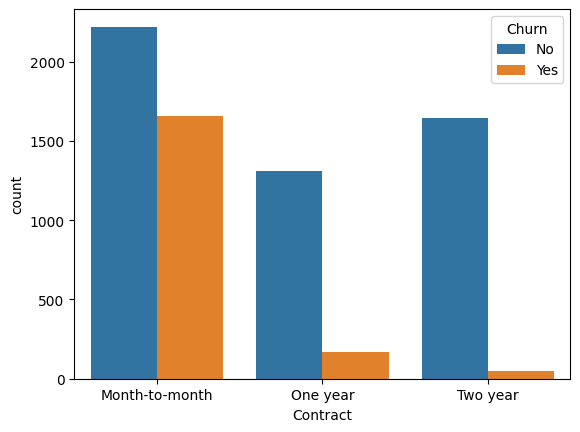

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(
    data=df,
    x="Contract",
    hue="Churn"
)

In [12]:
contract_churn = (
    pd.crosstab(
        df["Contract"],
        df["Churn"],
        normalize="index"
    ) * 100
)

contract_churn

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


<Axes: xlabel='Churn', ylabel='tenure'>

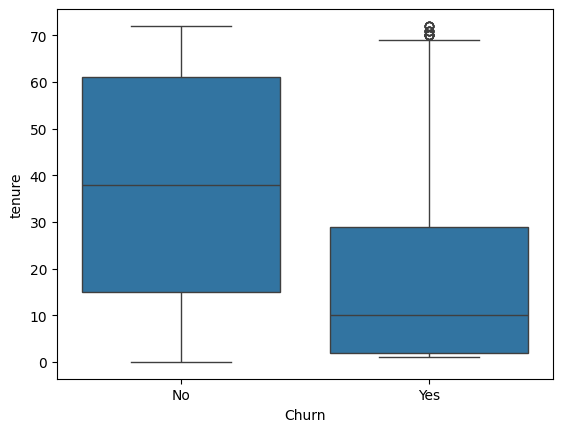

In [13]:
sns.boxplot(
    data=df,
    x="Churn",
    y="tenure"
)

In [14]:
df.groupby("Churn")["tenure"].agg(
    ["mean", "median", "min", "max"]
)

,mean,median,min,max
Churn,,,,
No,37.569965,38.0,0,72
Yes,17.979133,10.0,1,72


In [15]:
df.groupby("Churn")["MonthlyCharges"].agg(
    ["mean", "median", "min", "max"]
)

,mean,median,min,max
Churn,,,,
No,61.265124,64.425,18.25,118.75
Yes,74.441332,79.650,18.85,118.35


<Axes: xlabel='Churn', ylabel='MonthlyCharges'>

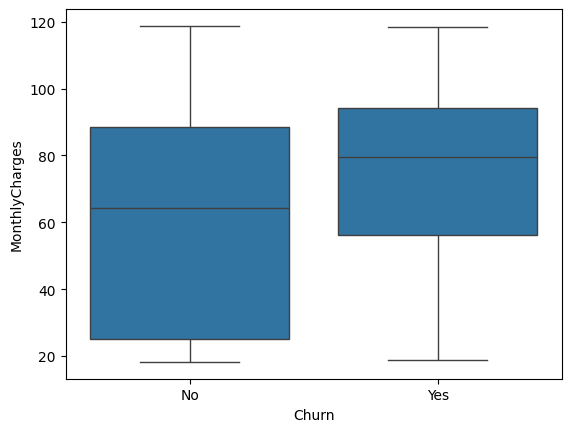

In [16]:
sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

In [17]:
df.groupby(["Contract", "Churn"])["MonthlyCharges"].agg(
    ["mean", "median", "count"]
)

mean  median  count
Contract       Churn                          
Month-to-month No     61.462635  64.950   2220
               Yes    73.019396  79.050   1655
One year       No     62.508148  64.850   1307
               Yes    85.050904  95.050    166
Two year       No     60.012477  63.300   1647
               Yes    86.777083  97.275     48

<Axes: xlabel='Contract', ylabel='MonthlyCharges'>

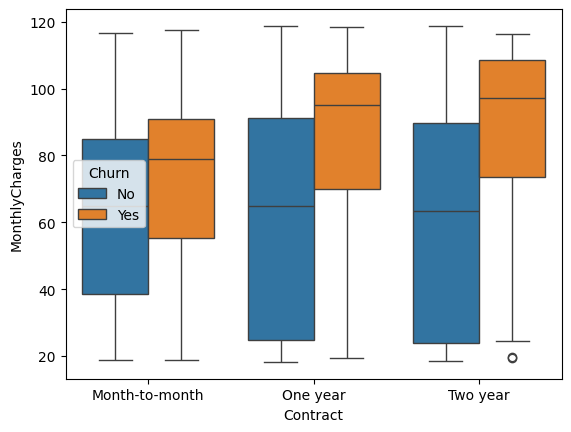

In [18]:
sns.boxplot(
    data=df,
    x="Contract",
    y="MonthlyCharges",
    hue="Churn"
)

In [19]:
categorical_columns = df.select_dtypes(include="object").columns.drop(
    ["customerID", "Churn"]
)

churn_rates = {}

for col in categorical_columns:
    churn_rates[col] = (
        pd.crosstab(
            df[col],
            df["Churn"],
            normalize="index"
        )["Yes"] * 100
    )

churn_rates

{'gender': gender
 Female    26.920872
 Male      26.160338
 Name: Yes, dtype: float64,
 'Partner': Partner
 No     32.957979
 Yes    19.664903
 Name: Yes, dtype: float64,
 'Dependents': Dependents
 No     31.279140
 Yes    15.450237
 Name: Yes, dtype: float64,
 'PhoneService': PhoneService
 No     24.926686
 Yes    26.709637
 Name: Yes, dtype: float64,
 'MultipleLines': MultipleLines
 No                  25.044248
 No phone service    24.926686
 Yes                 28.609896
 Name: Yes, dtype: float64,
 'InternetService': InternetService
 DSL            18.959108
 Fiber optic    41.892765
 No              7.404980
 Name: Yes, dtype: float64,
 'OnlineSecurity': OnlineSecurity
 No                     41.766724
 No internet service     7.404980
 Yes                    14.611194
 Name: Yes, dtype: float64,
 'OnlineBackup': OnlineBackup
 No                     39.928756
 No internet service     7.404980
 Yes                    21.531494
 Name: Yes, dtype: float64,
 'DeviceProtection': Devi

In [20]:
numeric_columns = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

df[numeric_columns].corr()

,tenure,MonthlyCharges,TotalCharges
tenure,1.000000,0.247900,0.826178
MonthlyCharges,0.247900,1.000000,0.651174
TotalCharges,0.826178,0.651174,1.000000


<Axes: >

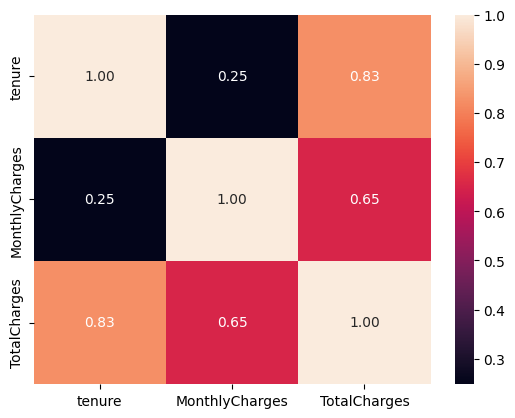

In [21]:
sns.heatmap(
    df[numeric_columns].corr(),
    annot=True,
    fmt=".2f"
)

In [22]:
X = df.drop(columns=["customerID", "Churn"])
y = df["Churn"]

In [23]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [24]:
X_train.shape, X_test.shape

((5634, 19), (1409, 19))

In [25]:
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_features = X.select_dtypes(
    include="object"
).columns

numeric_features, categorical_features

(Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='object'),
 Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
        'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
        'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
        'PaperlessBilling', 'PaymentMethod'],
       dtype='object'))

In [26]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_transformer = Pipeline(
    steps=[
        ("scaler", StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [27]:
from sklearn.linear_model import LogisticRegression

model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000))
    ]
)

In [28]:
model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod'],
      dtype='object'))])),
                ('classifier', LogisticRegression(max_iter=1000))])

In [29]:
y_pred = model.predict(X_test)
y_pred[:10]

array(['No', 'Yes', 'No', 'No', 'No', 'Yes', 'No', 'No', 'No', 'No'],
      dtype=object)

In [30]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    pos_label="Yes"
)

recall = recall_score(
    y_test,
    y_pred,
    pos_label="Yes"
)

f1 = f1_score(
    y_test,
    y_pred,
    pos_label="Yes"
)

accuracy, precision, recall, f1

(0.8055358410220014,
 0.6572327044025157,
 0.5588235294117647,
 0.6040462427745664)

In [31]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

          No       0.85      0.89      0.87      1035
         Yes       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



In [32]:
classification_report(y_test, y_pred)

'              precision    recall  f1-score   support\n\n          No       0.85      0.89      0.87      1035\n         Yes       0.66      0.56      0.60       374\n\n    accuracy                           0.81      1409\n   macro avg       0.75      0.73      0.74      1409\nweighted avg       0.80      0.81      0.80      1409\n'

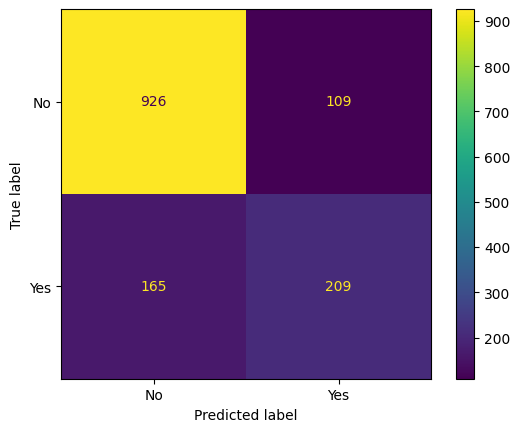

In [33]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["No", "Yes"]
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No", "Yes"]
).plot()

In [34]:
cm

array([[926, 109],
       [165, 209]])

In [35]:
y_prob = model.predict_proba(X_test)[:, 1]

In [36]:
from sklearn.metrics import roc_auc_score, RocCurveDisplay

roc_auc = roc_auc_score(
    y_test,
    y_prob
)

roc_auc

np.float64(0.8421349040274871)

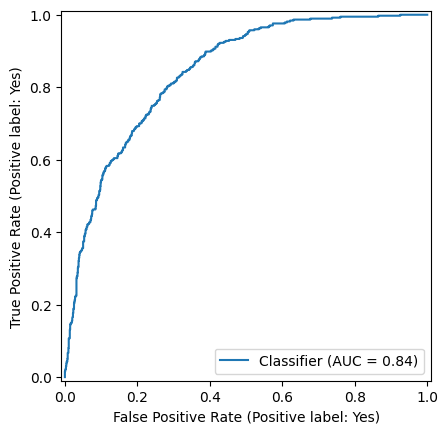

In [37]:
RocCurveDisplay.from_predictions(
    y_test,
    y_prob,
    pos_label="Yes"
)

In [38]:
thresholds = np.arange(0.1, 0.91, 0.05)

results = []

for threshold in thresholds:
    y_pred_threshold = np.where(
        y_prob >= threshold,
        "Yes",
        "No"
    )

    results.append({
        "threshold": threshold,
        "precision": precision_score(
            y_test,
            y_pred_threshold,
            pos_label="Yes",
            zero_division=0
        ),
        "recall": recall_score(
            y_test,
            y_pred_threshold,
            pos_label="Yes",
            zero_division=0
        ),
        "f1": f1_score(
            y_test,
            y_pred_threshold,
            pos_label="Yes",
            zero_division=0
        )
    })

threshold_results = pd.DataFrame(results)

threshold_results

,threshold,precision,recall,f1
0,0.10,0.405963,0.946524,0.568218
1,0.15,0.439589,0.914439,0.593750
2,0.20,0.467153,0.855615,0.604344
3,0.25,0.497537,0.810160,0.616480
4,0.30,0.519337,0.754011,0.615049
5,0.35,0.543210,0.705882,0.613953
6,0.40,0.568182,0.668449,0.614251
7,0.45,0.602094,0.614973,0.608466
8,0.50,0.657233,0.558824,0.604046
9,0.55,0.678431,0.462567,0.550079


In [39]:
from sklearn.metrics import make_scorer
from sklearn.model_selection import cross_validate

scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(
        precision_score,
        pos_label="Yes"
    ),
    "recall": make_scorer(
        recall_score,
        pos_label="Yes"
    ),
    "f1": make_scorer(
        f1_score,
        pos_label="Yes"
    ),
    "roc_auc": "roc_auc"
}

cv_results = cross_validate(
    model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

cv_results

NameError: name 'cv' is not defined

In [ ]:
cv_summary = pd.DataFrame({
    metric: [
        cv_results[f"test_{metric}"].mean(),
        cv_results[f"test_{metric}"].std()
    ]
    
    for metric in scoring
},
    index=["mean", "std"]
)

cv_summary

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=300,
                random_state=42,
                n_jobs=-1,
                class_weight="balanced"
            )
        )
    ]
)

In [ ]:
rf_cv_results = cross_validate(
    rf_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

In [ ]:
rf_cv_summary = pd.DataFrame({
    metric: [
        rf_cv_results[f"test_{metric}"].mean(),
        rf_cv_results[f"test_{metric}"].std()
    ]
    for metric in scoring
},
    index=["mean", "std"]
)

rf_cv_summary

In [ ]:
comparison = pd.DataFrame({
    "Logistic Regression": {
        metric: cv_results[f"test_{metric}"].mean()
        for metric in scoring
    },
    "Random Forest": {
        metric: rf_cv_results[f"test_{metric}"].mean()
        for metric in scoring
    }
}).T

comparison

In [ ]:
comparison = pd.DataFrame({
    "Logistic Regression": {
        metric: cv_results[f"test_{metric}"].mean()
        for metric in scoring
    },
    "Random Forest": {
        metric: rf_cv_results[f"test_{metric}"].mean()
        for metric in scoring
    }
}).T

comparison

In [ ]:
from catboost import CatBoostClassifier
cat_model = CatBoostClassifier(
    iterations=500,
    learning_rate=0.05,
    depth=6,
    loss_function="Logloss",
    eval_metric="AUC",
    verbose=0,
    random_state=42
)

In [ ]:
cat_feature_indices = [
    X.columns.get_loc(col)
    for col in categorical_features
]

cat_feature_indices

In [ ]:
cat_model = CatBoostClassifier(
    iterations=500,
    learning_rate=0.05,
    depth=6,
    loss_function="Logloss",
    eval_metric="AUC",
    cat_features=cat_feature_indices,
    verbose=0,
    random_state=42
)

In [ ]:
cat_feature_indices = tuple(cat_feature_indices)

cat_model = CatBoostClassifier(
    iterations=500,
    learning_rate=0.05,
    depth=6,
    loss_function="Logloss",
    eval_metric="AUC",
    cat_features=cat_feature_indices,
    verbose=0,
    random_state=42
)

In [ ]:
cat_cv_results = cross_validate(
    cat_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=False,
    error_score="raise"
)

In [ ]:
cat_cv_summary = pd.DataFrame({
    metric: [
        cat_cv_results[f"test_{metric}"].mean(),
        cat_cv_results[f"test_{metric}"].std()
    ]
    for metric in scoring
},
    index=["mean", "std"]
)

cat_cv_summary

In [ ]:
from sklearn.model_selection import ParameterGrid

param_grid = {
    "depth": [4, 6, 8],
    "learning_rate": [0.03, 0.05],
    "l2_leaf_reg": [3, 5]
}

param_combinations = list(ParameterGrid(param_grid))

len(param_combinations)

In [ ]:
tuning_results = []

for params in param_combinations:
    
    model = CatBoostClassifier(
        iterations=500,
        loss_function="Logloss",
        eval_metric="AUC",
        cat_features=cat_feature_indices,
        verbose=0,
        random_state=42,
        **params
    )
    
    results = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        return_train_score=False
    )
    
    tuning_results.append({
        **params,
        "accuracy": results["test_accuracy"].mean(),
        "precision": results["test_precision"].mean(),
        "recall": results["test_recall"].mean(),
        "f1": results["test_f1"].mean(),
        "roc_auc": results["test_roc_auc"].mean()
    })

tuning_results = pd.DataFrame(tuning_results)

tuning_results.sort_values(
    by="roc_auc",
    ascending=False
).reset_index(drop=True)

In [ ]:
best_cat_model = CatBoostClassifier(
    iterations=500,
    depth=4,
    learning_rate=0.03,
    l2_leaf_reg=3,
    loss_function="Logloss",
    eval_metric="AUC",
    cat_features=cat_feature_indices,
    verbose=0,
    random_state=42
)

In [ ]:
from sklearn.model_selection import cross_val_predict

oof_prob = cross_val_predict(
    best_cat_model,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba"
)[:, 1]

In [ ]:
from sklearn.model_selection import cross_val_predict

oof_prob = cross_val_predict(
    best_cat_model,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba"
)[:, 1]

In [ ]:
thresholds = np.arange(0.10, 0.71, 0.01)

threshold_results = []

for threshold in thresholds:
    y_pred_threshold = np.where(
        oof_prob >= threshold,
        "Yes",
        "No"
    )

    threshold_results.append({
        "threshold": threshold,
        "precision": precision_score(
            y_train,
            y_pred_threshold,
            pos_label="Yes",
            zero_division=0
        ),
        "recall": recall_score(
            y_train,
            y_pred_threshold,
            pos_label="Yes",
            zero_division=0
        ),
        "f1": f1_score(
            y_train,
            y_pred_threshold,
            pos_label="Yes",
            zero_division=0
        )
    })

threshold_results = pd.DataFrame(threshold_results)

threshold_results.sort_values(
    by="f1",
    ascending=False
).head(10)

In [ ]:
best_cat_model.fit(
    X_train,
    y_train
)

In [ ]:
test_prob = best_cat_model.predict_proba(
    X_test
)[:, 1]

In [ ]:
final_threshold = 0.37

test_pred = np.where(
    test_prob >= final_threshold,
    "Yes",
    "No"
)

In [ ]:
final_metrics = {
    "accuracy": accuracy_score(
        y_test,
        test_pred
    ),
    "precision": precision_score(
        y_test,
        test_pred,
        pos_label="Yes"
    ),
    "recall": recall_score(
        y_test,
        test_pred,
        pos_label="Yes"
    ),
    "f1": f1_score(
        y_test,
        test_pred,
        pos_label="Yes"
    ),
    "roc_auc": roc_auc_score(
        y_test,
        test_prob
    )
}

pd.Series(final_metrics)

In [ ]:
print(
    classification_report(
        y_test,
        test_pred
    )
)

In [ ]:
pd.Series(final_metrics)

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

final_cm = confusion_matrix(
    y_test,
    test_pred,
    labels=["No", "Yes"]
)

ConfusionMatrixDisplay(
    confusion_matrix=final_cm,
    display_labels=["No", "Yes"]
).plot()

In [ ]:
final_cm

In [ ]:
feature_importance = pd.DataFrame({
    "feature": X_train.columns,
    "importance": best_cat_model.get_feature_importance()
}).sort_values(
    by="importance",
    ascending=False
)

feature_importance

In [ ]:
top_features = feature_importance.head(10)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=top_features,
    x="importance",
    y="feature"
)